# Klasifikasi Citra Sepatu (Rapi vs. Berantakan)
### Notebook Lengkap: Ekstraksi Fitur Multimodal, Pemodelan, Evaluasi, dan Penerapan Model (Kerangka CRISP-DM)

---

## Ringkasan Proyek

| Parameter | Keterangan |
| :--- | :--- |
| **Domain** | Pengolahan Citra Digital (*Computer Vision*) dan *Machine Learning* klasik (tanpa *neural network*) |
| **Kasus** | Klasifikasi biner foto susunan sepatu: **Rapi** vs. **Berantakan** |
| **Dataset** | Folder `citra/rapi` dan `citra/berantakan` |
| **Preprocessing** | Konversi BGR → RGB, *resize* 256 × 256, grayscale 8 bit |
| **Fitur tugas (14)** | Statistik warna orde pertama RGB (9) + tekstur GLCM orde kedua (5) |
| **Fitur revisi (+39)** | Warna HSV (9), tepi (4), kontur dan bentuk (6), orientasi gradien (10), pita spasial (5), titik kunci ORB (3), tekstur LBP (2) |
| **Total fitur** | **53 fitur** + label |
| **Pembagian data** | 80% latih : 20% uji, *stratified sampling* |
| **Eksperimen** | (1) 14 fitur tugas, (2) 53 fitur, (3) 53 fitur + seleksi fitur ANOVA |
| **Model** | 5 model standar + 4 model *ensemble* |
| **Keluaran** | Folder `hasil2/` (CSV fitur, hasil evaluasi, model tersimpan) dan `grayscale/` |

### Asal Fitur Revisi
Fitur tambahan diambil dari dua contoh proyek kelompok lain yang sudah direvisi dosen:

| Kelompok fitur | Diambil dari | Alasan dipakai |
| :--- | :--- | :--- |
| Tepi, kontur & momen Hu, orientasi gradien | Repo GitHub kelompok lain (`main.ipynb` 48 fitur) | mengukur bentuk, batas objek, dan arah garis (rapi = sejajar rak) |
| Warna HSV, pita spasial, ORB, LBP | Notebook CRISP-DM kelompok lain (44 fitur) | warna yang lebih tahan perubahan cahaya, letak keramaian (lantai vs. rak), titik sudut, tekstur mikro |
| ~~SIFT + Bag of Visual Words~~ | Repo GitHub kelompok lain | **tidak dipakai**: kamus visual (K-Means) dibentuk dari seluruh data sebelum pembagian latih/uji, sehingga informasi data uji ikut bocor ke data latih |
| ~~CIELAB~~ | Notebook CRISP-DM kelompok lain | **tidak dipakai**: informasinya tumpang tindih dengan RGB dan HSV |

### Alur Notebook
| Tahap CRISP-DM | Isi |
| :--- | :--- |
| 1. Business Understanding | Latar belakang, rumusan masalah, tujuan |
| 2. Data Understanding | Jumlah data, sampel visual |
| 3. Data Preparation | Preprocessing, ekstraksi 14 fitur tugas + 39 fitur revisi, penyimpanan CSV, analisis awal |
| 4. Modeling | Pembagian data, definisi 9 model, 3 eksperimen |
| 5. Evaluation | Perbandingan eksperimen, validasi silang, *confusion matrix*, *overfitting*, *feature importance* |
| 6. Deployment | Penyimpanan model dan fungsi prediksi citra baru |

---

## TAHAP 1: BUSINESS UNDERSTANDING (Pemahaman Masalah)

### 1.1 Latar Belakang
Kerapian susunan sepatu dinilai secara visual dan subjektif. Agar dapat dinilai komputer, setiap foto diubah menjadi **fitur numerik**, lalu model *machine learning* belajar membedakan kedua kelas dari fitur tersebut.

### 1.2 Mengapa Fitur Perlu Ditambah?
Pada versi tugas, hanya dipakai 14 fitur (statistik warna RGB dan GLCM). Fitur-fitur ini meringkas **warna dan tekstur seluruh gambar**, padahal perbedaan rapi dan berantakan terletak pada **susunan objek**:
- **Rapi**: sepatu berjajar sejajar di rak, garis-garis lurus mendatar dan tegak, lantai relatif kosong.
- **Berantakan**: sepatu tersebar dan miring di lantai, saling menumpuk, banyak tepi dan sudut acak di bagian bawah foto.

Fitur revisi dirancang untuk menangkap ciri susunan ini secara langsung.

### 1.3 Rumusan Masalah
1. Bagaimana mengekstraksi 14 fitur tugas dan 39 fitur tambahan dari citra sepatu?
2. Apakah penambahan fitur meningkatkan akurasi klasifikasi dibanding 14 fitur tugas?
3. Model mana yang paling baik membedakan sepatu rapi dan berantakan?

### 1.4 Tujuan
- Menghasilkan tabel fitur dalam format CSV di folder `hasil2/`.
- Membandingkan 9 model pada tiga skenario fitur.
- Menyimpan model terbaik beserta fungsi prediksi untuk citra baru.

---

## Inisialisasi & Konfigurasi

| Variabel | Nilai | Fungsi |
| :--- | :--- | :--- |
| `FOLDER_CITRA` | `citra` | dataset, berisi subfolder `rapi` dan `berantakan` |
| `FOLDER_GRAY` | `grayscale` | hasil konversi grayscale |
| `FOLDER_HASIL` | `hasil2` | semua keluaran notebook ini (CSV, gambar, model) |
| `UKURAN` | 256 × 256 | ukuran standar citra |

In [1]:
import os

FOLDER_CITRA = "citra"
FOLDER_GRAY = "grayscale"
FOLDER_HASIL = "hasil2"
KELAS = ["rapi", "berantakan"]
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
UKURAN = (256, 256)

for folder in [FOLDER_HASIL] + [os.path.join(FOLDER_GRAY, k) for k in KELAS]:
    os.makedirs(folder, exist_ok=True)

print("Folder proyek  :", os.path.abspath("."))
print("Folder dataset :", os.path.abspath(FOLDER_CITRA))
print("Folder keluaran:", os.path.abspath(FOLDER_HASIL))

Folder proyek  : c:\project\image-classification
Folder dataset : c:\project\image-classification\citra
Folder keluaran: c:\project\image-classification\hasil2


---

## TAHAP 2: DATA UNDERSTANDING (Pemahaman Data)

### 2.1 Jumlah Citra per Kelas
Label diambil dari nama subfolder. Setiap citra diberi `id` berurutan.

In [2]:
import os
import pandas as pd

baris = []
for kelas in KELAS:
    folder = os.path.join(FOLDER_CITRA, kelas)
    for nama in sorted(os.listdir(folder)):
        if nama.lower().endswith(EKSTENSI):
            baris.append({"nama_file": nama, "label": kelas, "path": os.path.join(folder, nama)})

df = pd.DataFrame(baris)
df.insert(0, "id", range(1, len(df) + 1))

print("=== RINGKASAN DATASET ===")
print("Total citra:", len(df))
print(df["label"].value_counts().to_string())

=== RINGKASAN DATASET ===
Total citra: 194
label
rapi          97
berantakan    97


### 2.2 Sampel Visual Dataset

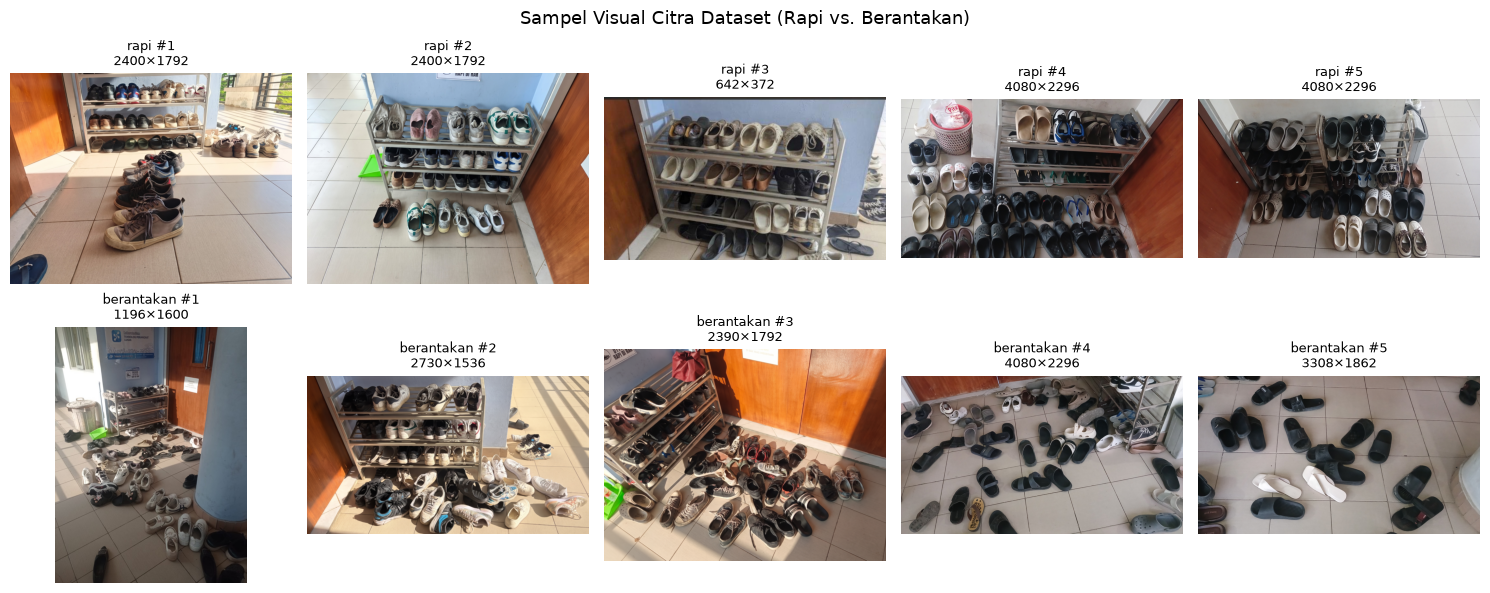

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca_citra(path):
    """Baca citra berwarna (BGR). imdecode dipakai sebagai cadangan untuk path Windows."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    return img

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for b, kelas in enumerate(KELAS):
    for k, (_, r) in enumerate(df[df["label"] == kelas].head(5).iterrows()):
        img = baca_citra(r["path"])
        axes[b, k].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[b, k].set_title(f"{kelas} #{k + 1}\n{img.shape[1]}×{img.shape[0]}", fontsize=9)
        axes[b, k].axis("off")
plt.suptitle("Sampel Visual Citra Dataset (Rapi vs. Berantakan)", fontsize=13)
plt.tight_layout()
plt.show()

---

## TAHAP 3: DATA PREPARATION (Preprocessing & Ekstraksi Fitur)

### 3.1 Preprocessing dan Konversi Grayscale
1. **BGR → RGB**: OpenCV membaca kanal dengan urutan Biru-Hijau-Merah.
2. **Resize 256 × 256** (`INTER_AREA`): ukuran foto antar-anggota berbeda jauh; ukuran seragam membuat fitur dapat dibandingkan.
3. **Grayscale 8 bit**:
$$Gray = 0.299\,R + 0.587\,G + 0.114\,B$$
   dibulatkan ke 0–255 ($2^8 = 256$ level), lalu disimpan ke folder `grayscale/` (PNG).

Citra diproses        : 194
Ukuran RGB / grayscale: (256, 256, 3) / (256, 256)
Grayscale disimpan ke : grayscale/


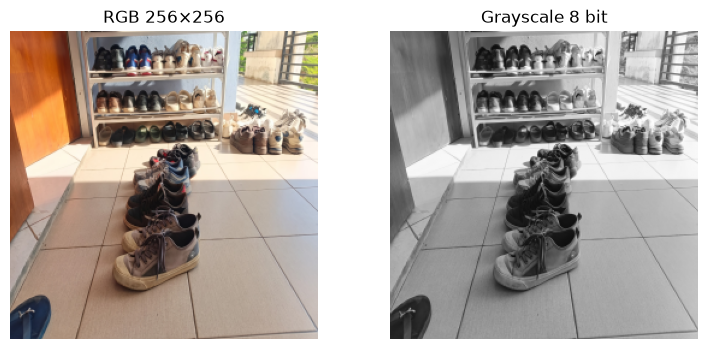

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def preprocessing(path):
    img = cv2.cvtColor(baca_citra(path), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, UKURAN, interpolation=cv2.INTER_AREA)

def ke_gray(rgb):
    r, g, b = [rgb[:, :, i].astype(np.float64) for i in range(3)]
    return np.clip(np.round(0.299 * r + 0.587 * g + 0.114 * b), 0, 255).astype(np.uint8)

citra_rgb = {r["id"]: preprocessing(r["path"]) for _, r in df.iterrows()}
citra_gray = {i: ke_gray(citra_rgb[i]) for i in df["id"]}

for _, r in df.iterrows():
    out = os.path.join(FOLDER_GRAY, r["label"], os.path.splitext(r["nama_file"])[0] + ".png")
    cv2.imencode(".png", citra_gray[r["id"]])[1].tofile(out)

print("Citra diproses        :", len(citra_rgb))
print("Ukuran RGB / grayscale:", citra_rgb[1].shape, "/", citra_gray[1].shape)
print("Grayscale disimpan ke :", FOLDER_GRAY + "/")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(citra_rgb[1]);                                 axes[0].set_title("RGB 256×256")
axes[1].imshow(citra_gray[1], cmap="gray", vmin=0, vmax=255); axes[1].set_title("Grayscale 8 bit")
for ax in axes: ax.axis("off")
plt.show()

### 3.2 Fitur Tugas A — Statistik Warna Orde Pertama RGB (9 Fitur)
Untuk kanal $C \in \{R, G, B\}$ pada citra $M \times N$:

| Fitur | Rumus | Makna |
| :--- | :--- | :--- |
| `mean_*`, Pers. (2) | $\mu_C = \frac{1}{MN}\sum_{i,j} C(i,j)$ | kecerahan rata-rata kanal |
| `std_*`, Pers. (3) | $\sigma_C = \sqrt{\frac{1}{MN}\sum_{i,j}(C(i,j)-\mu_C)^2}$ | keragaman/kontras warna |
| `skew_*`, Pers. (4) | $\frac{1}{MN}\sum_{i,j}\left(\frac{C(i,j)-\mu_C}{\sigma_C}\right)^3$ | kemencengan sebaran nilai piksel |

Rumus ditulis manual sesuai slide dan dicocokkan dengan `numpy`/`scipy`.

In [5]:
import numpy as np
from scipy.stats import skew

def mean_kanal(x):
    return x.sum() / x.size

def std_kanal(x):
    return np.sqrt(np.sum((x - mean_kanal(x)) ** 2) / x.size)

def skew_kanal(x):
    mu, sd = mean_kanal(x), std_kanal(x)
    return 0.0 if sd == 0 else np.sum(((x - mu) / sd) ** 3) / x.size

def fitur_rgb(rgb):
    f = {}
    for stat, fungsi in [("mean", mean_kanal), ("std", std_kanal), ("skew", skew_kanal)]:
        for i, kanal in enumerate("rgb"):
            f[f"{stat}_{kanal}"] = fungsi(rgb[:, :, i].astype(np.float64))
    return f

R = citra_rgb[1][:, :, 0].astype(np.float64)
print(f"Manual  -> mean_r: {mean_kanal(R):.4f} | std_r: {std_kanal(R):.4f} | skew_r: {skew_kanal(R):.4f}")
print(f"Library -> mean_r: {R.mean():.4f} | std_r: {R.std():.4f} | skew_r: {skew(R.ravel()):.4f}")

Manual  -> mean_r: 167.5277 | std_r: 58.7598 | skew_r: -0.7423
Library -> mean_r: 167.5277 | std_r: 58.7598 | skew_r: -0.7423


### 3.3 Fitur Tugas B — Matriks Co-occurrence (GLCM) dan Tekstur Orde Kedua (5 Fitur)

#### Matriks Co-occurrence
GLCM mencatat seberapa sering pasangan nilai keabuan $(i, j)$ muncul berdampingan. Parameter sesuai modul: jarak $d = 1$, sudut $\theta = 0^\circ$, 256 level, `symmetric=False`, `normed=True`, sehingga
$$P(i,j) = \frac{GLCM(i,j)}{\sum_{i,j} GLCM(i,j)}$$

#### Fitur Tekstur
| Fitur | Rumus | Makna |
| :--- | :--- | :--- |
| `energi`, Pers. (8) | $\sum_{i,j} P(i,j)^2$ | tinggi = tekstur seragam |
| `entropi`, Pers. (5) | $-\sum_{i,j} P(i,j)\log_2 P(i,j)$ | tinggi = tekstur acak |
| `kontras`, Pers. (6) | $\sum_{i,j} (i-j)^2 P(i,j)$ | tinggi = banyak perubahan tajam |
| `korelasi`, Pers. (7) | $\sum_{i,j} \frac{(i-\mu_i)(j-\mu_j)P(i,j)}{\sigma_i\sigma_j}$ | keterkaitan linier piksel bertetangga |
| `homogenitas`, Pers. (9) | $\sum_{i,j} \frac{P(i,j)}{1+\lvert i-j\rvert}$ | tinggi = transisi halus |

Kode dicek dulu dengan contoh citra 3 × 3 dari modul.

In [6]:
import numpy as np
from skimage.feature import graycomatrix

def buat_glcm(gray, levels=256, normed=True):
    return graycomatrix(gray, distances=[1], angles=[0], levels=levels, symmetric=False, normed=normed)

def fitur_glcm(gray, levels=256):
    P = buat_glcm(gray, levels=levels)[:, :, 0, 0]
    i, j = np.indices(P.shape)
    nz = P[P > 0]
    mu_i, mu_j = np.sum(i * P), np.sum(j * P)
    sd_i = np.sqrt(np.sum((i - mu_i) ** 2 * P))
    sd_j = np.sqrt(np.sum((j - mu_j) ** 2 * P))
    return {
        "energi": np.sum(P ** 2),
        "entropi": -np.sum(nz * np.log2(nz)),
        "kontras": np.sum((i - j) ** 2 * P),
        "korelasi": 1.0 if sd_i * sd_j == 0 else np.sum((i - mu_i) * (j - mu_j) * P) / (sd_i * sd_j),
        "homogenitas": np.sum(P / (1 + np.abs(i - j))),
    }

contoh = np.array([[0, 1, 1], [0, 2, 1], [2, 2, 0]], dtype=np.uint8)
print("GLCM mentah contoh 3x3:\n", buat_glcm(contoh, levels=3, normed=False)[:, :, 0, 0])
print("Fitur contoh 3x3      :", {k: round(float(v), 4) for k, v in fitur_glcm(contoh, levels=3).items()})
print("Ukuran GLCM citra     :", buat_glcm(citra_gray[1]).shape[:2])

GLCM mentah contoh 3x3:
 [[0 1 1]
 [0 1 0]
 [1 1 1]]
Fitur contoh 3x3      : {'energi': 0.1667, 'entropi': 2.585, 'kontras': 1.6667, 'korelasi': -0.3153, 'homogenitas': 0.6111}
Ukuran GLCM citra     : (256, 256)


### 3.4 Fitur Revisi

#### A. Statistik Warna HSV (9 Fitur: `mean_h`, `mean_s`, `mean_v`, `std_*`, `skew_*`)
- **Pengertian**: Ruang warna **Hue** (jenis warna, 0–179 di OpenCV), **Saturation** (kepekatan warna, 0–255), dan **Value** (kecerahan, 0–255). *Mean*, standar deviasi, dan *skewness* dihitung pada tiap kanal, sama seperti RGB.
- **Relevansi**: Pada RGB, perubahan cahaya (lampu kuning/putih, siang/malam) mengubah ketiga kanal sekaligus. HSV memisahkan warna (H, S) dari kecerahan (V), sehingga warna sepatu dan lantai lebih konsisten antar-foto.

#### B. Fitur Tepi (4 Fitur)
| Fitur | Isi |
| :--- | :--- |
| `edge_density` | proporsi piksel tepi hasil detektor **Canny** (ambang 50 dan 150) |
| `sobel_mean`, `sobel_std` | rata-rata dan standar deviasi besar gradien **Sobel**, $\lvert\nabla I\rvert = \sqrt{G_x^2 + G_y^2}$ |
| `laplacian_var` | variansi turunan kedua $\nabla^2 I$ (**Laplacian**), mengukur ketajaman batas objek |

- **Relevansi**: Sepatu berserakan menghasilkan lebih banyak tepi acak dibanding rak yang tertata.

#### C. Fitur Kontur dan Bentuk (6 Fitur)
| Fitur | Isi |
| :--- | :--- |
| `num_contours` | jumlah kontur luar pada peta tepi Canny |
| `contour_area_mean`, `contour_area_std` | rata-rata dan standar deviasi luas kontur (luas > 10 piksel) |
| `contour_solidity` | rata-rata $\frac{A}{A_{\text{convex hull}}}$; sepatu menumpuk membentuk lekukan sehingga nilainya kecil |
| `hu_1`, `hu_2` | dua momen Hu pertama (tidak berubah terhadap geser, skala, rotasi), skala log |

#### D. Fitur Orientasi Gradien (10 Fitur)
Arah gradien $\theta = \arctan(G_y / G_x)$ (0°–180°) dikelompokkan ke 8 bin selebar 22,5°, dibobot besar gradien, lalu dinormalisasi.

| Fitur | Isi |
| :--- | :--- |
| `orient_bin0` … `orient_bin7` | proporsi gradien di tiap rentang sudut |
| `orient_entropi` | keacakan arah garis |
| `orient_ortho` | proporsi gradien mendatar/tegak (bin 0, 3, 4, 7); rak rapi didominasi garis lurus |

Ini histogram arah gradien untuk seluruh gambar, **bukan** HOG lengkap (HOG dihitung per sel dan per blok).

#### E. Fitur Pita Spasial (5 Fitur)
Peta tepi Canny dibagi tiga pita mendatar: **atas** (rak/dinding), **tengah**, **bawah** (lantai).

| Fitur | Isi |
| :--- | :--- |
| `band_atas`, `band_tengah`, `band_bawah` | kepadatan tepi tiap pita |
| `rasio_bawah_atas`, `rasio_tengah_atas` | perbandingan kepadatan tepi pita bawah/tengah terhadap pita atas |

- **Relevansi**: Sepatu berantakan umumnya tersebar di lantai, sehingga kepadatan tepi pita bawah relatif tinggi.

#### F. Fitur Titik Kunci ORB (3 Fitur)
- **Pengertian**: **ORB** (*Oriented FAST and Rotated BRIEF*) mendeteksi titik sudut yang mencolok.
- **Fitur**: `orb_total` (jumlah titik), `orb_bawah` (jumlah titik di sepertiga bawah), `orb_rasio_bawah` (proporsi titik di bagian bawah).
- **Relevansi**: Tali, sol, dan sepatu yang bertumpuk memunculkan banyak titik sudut di lantai.

#### G. Fitur Tekstur Mikro LBP (2 Fitur)
- **Pengertian**: **LBP** (*Local Binary Pattern*, $P = 8$, $R = 1$, *uniform*) membandingkan setiap piksel dengan 8 tetangganya dan menghasilkan kode pola 0–9.
- **Fitur**: `lbp_mean`, `lbp_std` (rata-rata dan standar deviasi kode LBP).
- **Relevansi**: Membedakan tekstur halus (lantai, rak) dari tekstur rumit (tumpukan sepatu).

In [7]:
import cv2
import numpy as np
from scipy.stats import skew
from skimage.feature import local_binary_pattern

def fitur_hsv(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).astype(np.float64)
    f = {}
    for stat, fungsi in [("mean", np.mean), ("std", np.std), ("skew", lambda x: skew(x.ravel()))]:
        for i, kanal in enumerate("hsv"):
            f[f"{stat}_{kanal}"] = fungsi(hsv[:, :, i])
    return f

def gradien(gray):
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return gx, gy, np.hypot(gx, gy)

def fitur_tepi_kontur(gray):
    canny = cv2.Canny(gray, 50, 150)
    _, _, mag = gradien(gray)
    kontur, _ = cv2.findContours(canny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    luas = np.array([cv2.contourArea(c) for c in kontur])
    besar = [c for c, a in zip(kontur, luas) if a > 10]
    soliditas = [cv2.contourArea(c) / cv2.contourArea(cv2.convexHull(c))
                 for c in besar if cv2.contourArea(cv2.convexHull(c)) > 0]
    hu = cv2.HuMoments(cv2.moments(canny, binaryImage=True)).ravel()
    return {
        "edge_density": (canny > 0).mean(),
        "sobel_mean": mag.mean(),
        "sobel_std": mag.std(),
        "laplacian_var": cv2.Laplacian(gray, cv2.CV_64F).var(),
        "num_contours": len(kontur),
        "contour_area_mean": luas[luas > 10].mean() if besar else 0.0,
        "contour_area_std": luas[luas > 10].std() if besar else 0.0,
        "contour_solidity": np.mean(soliditas) if soliditas else 0.0,
        "hu_1": -np.sign(hu[0]) * np.log10(abs(hu[0]) + 1e-15),
        "hu_2": -np.sign(hu[1]) * np.log10(abs(hu[1]) + 1e-15),
    }

def fitur_orientasi(gray):
    gx, gy, mag = gradien(gray)
    sudut = np.degrees(np.arctan2(gy, gx)) % 180
    hist, _ = np.histogram(sudut, bins=8, range=(0, 180), weights=mag)
    h = hist / hist.sum() if hist.sum() > 0 else np.zeros(8)
    nz = h[h > 0]
    f = {f"orient_bin{i}": v for i, v in enumerate(h)}
    f["orient_entropi"] = -np.sum(nz * np.log2(nz))
    f["orient_ortho"] = h[[0, 3, 4, 7]].sum()
    return f

def fitur_spasial(gray):
    tepi = cv2.Canny(gray, 50, 150) > 0
    sepertiga = gray.shape[0] // 3
    atas, tengah, bawah = tepi[:sepertiga].mean(), tepi[sepertiga:2 * sepertiga].mean(), tepi[2 * sepertiga:].mean()
    return {"band_atas": atas, "band_tengah": tengah, "band_bawah": bawah,
            "rasio_bawah_atas": bawah / (atas + 1e-6), "rasio_tengah_atas": tengah / (atas + 1e-6)}

ORB = cv2.ORB_create(nfeatures=500)

def fitur_orb(gray):
    titik = ORB.detect(gray, None)
    total = len(titik)
    bawah = sum(1 for t in titik if t.pt[1] >= 2 * gray.shape[0] / 3)
    return {"orb_total": total, "orb_bawah": bawah, "orb_rasio_bawah": bawah / total if total else 0.0}

def fitur_lbp(gray):
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    return {"lbp_mean": lbp.mean(), "lbp_std": lbp.std()}

contoh_fitur = {**fitur_hsv(citra_rgb[1]), **fitur_tepi_kontur(citra_gray[1]), **fitur_orientasi(citra_gray[1]),
                **fitur_spasial(citra_gray[1]), **fitur_orb(citra_gray[1]), **fitur_lbp(citra_gray[1])}
print("Jumlah fitur revisi per citra:", len(contoh_fitur))
for k, v in contoh_fitur.items():
    print(f"  {k:18} = {v:.4f}")

Jumlah fitur revisi per citra: 39
  mean_h             = 28.1296
  mean_s             = 65.5850
  mean_v             = 169.4807
  std_h              = 38.4280
  std_s              = 49.8960
  std_v              = 57.7597
  skew_h             = 2.2951
  skew_s             = 1.4856
  skew_v             = -0.7091
  edge_density       = 0.1602
  sobel_mean         = 80.3363
  sobel_std          = 113.9880
  laplacian_var      = 1680.7878
  num_contours       = 206.0000
  contour_area_mean  = 124.4545
  contour_area_std   = 240.8789
  contour_solidity   = 0.2354
  hu_1               = 0.0677
  hu_2               = 1.3442
  orient_bin0        = 0.1421
  orient_bin1        = 0.0895
  orient_bin2        = 0.0925
  orient_bin3        = 0.1953
  orient_bin4        = 0.1601
  orient_bin5        = 0.0788
  orient_bin6        = 0.0876
  orient_bin7        = 0.1541
  orient_entropi     = 2.9250
  orient_ortho       = 0.6516
  band_atas          = 0.2361
  band_tengah        = 0.1452
  band_bawah    

### 3.5 Ekstraksi Seluruh Citra dan Penyimpanan CSV
Setiap kelompok fitur disimpan dalam CSV terpisah di `hasil2/`

In [8]:
import os
import pandas as pd

ekstraktor = {
    "rgb": lambda i: fitur_rgb(citra_rgb[i].astype(np.float64)),
    "glcm": lambda i: fitur_glcm(citra_gray[i]),
    "hsv": lambda i: fitur_hsv(citra_rgb[i]),
    "tepi_kontur": lambda i: fitur_tepi_kontur(citra_gray[i]),
    "orientasi": lambda i: fitur_orientasi(citra_gray[i]),
    "spasial": lambda i: fitur_spasial(citra_gray[i]),
    "orb": lambda i: fitur_orb(citra_gray[i]),
    "lbp": lambda i: fitur_lbp(citra_gray[i]),
}

identitas = df[["id", "nama_file"]]
kelompok = {}
for nama, fungsi in ekstraktor.items():
    tabel = pd.DataFrame([fungsi(i) for i in df["id"]]).round(8)
    kelompok[nama] = list(tabel.columns)
    pd.concat([identitas, tabel, df[["label"]]], axis=1).to_csv(
        os.path.join(FOLDER_HASIL, f"fitur_{nama}.csv"), index=False)
    if nama == "rgb":
        semua = tabel
    else:
        semua = pd.concat([semua, tabel], axis=1)
    print(f"fitur_{nama + '.csv':22} : {tabel.shape[1]:2d} fitur")

FITUR_TUGAS = kelompok["rgb"] + kelompok["glcm"]
FITUR_SEMUA = list(semua.columns)

fitur_semua = pd.concat([identitas, semua, df[["label"]]], axis=1)
fitur_semua[["id", "nama_file"] + FITUR_TUGAS + ["label"]].to_csv(os.path.join(FOLDER_HASIL, "fitur_tugas.csv"), index=False)
fitur_semua.to_csv(os.path.join(FOLDER_HASIL, "fitur_semua.csv"), index=False)

print(f"\nFitur tugas : {len(FITUR_TUGAS)}  -> {FOLDER_HASIL}/fitur_tugas.csv")
print(f"Fitur semua : {len(FITUR_SEMUA)}  -> {FOLDER_HASIL}/fitur_semua.csv")
print("Data kosong :", int(fitur_semua[FITUR_SEMUA].isna().sum().sum()))
fitur_semua.head()

fitur_rgb.csv                :  9 fitur
fitur_glcm.csv               :  5 fitur
fitur_hsv.csv                :  9 fitur
fitur_tepi_kontur.csv        : 10 fitur
fitur_orientasi.csv          : 10 fitur
fitur_spasial.csv            :  5 fitur
fitur_orb.csv                :  3 fitur
fitur_lbp.csv                :  2 fitur

Fitur tugas : 14  -> hasil2/fitur_tugas.csv
Fitur semua : 53  -> hasil2/fitur_semua.csv
Data kosong : 0


,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,...,band_tengah,band_bawah,rasio_bawah_atas,rasio_tengah_atas,orb_total,orb_bawah,orb_rasio_bawah,lbp_mean,lbp_std,label
0,1,24-003 Rapi 2.jpg,167.527710,145.621918,129.198227,58.759761,58.723771,59.402692,-0.742271,-0.338399,...,0.145221,0.099927,0.423284,0.615142,462,3,0.006494,5.121338,2.776685,rapi
1,2,24-003 Rapi 3.jpg,151.797928,144.180862,136.961426,54.870804,62.468708,69.736436,-0.612653,-0.299693,...,0.182445,0.101880,0.626067,1.121145,471,93,0.197452,5.032120,2.531152,rapi
2,3,24-003 Rapi.jpeg,112.611130,105.589966,102.377884,50.950499,56.403850,62.854712,0.046902,0.190023,...,0.181572,0.182322,1.274429,1.269185,455,118,0.259341,4.940292,2.425248,rapi
3,4,24-006 Rapi 1.jpg,99.661835,84.968781,82.130844,61.311796,59.815117,61.163300,0.308220,0.823607,...,0.185846,0.184775,0.965117,0.970710,458,72,0.157205,4.850815,2.433429,rapi
4,5,24-006 Rapi 2.jpg,111.911102,102.241302,99.273773,63.384317,66.315790,67.540660,-0.022268,0.230848,...,0.173805,0.155705,0.963629,1.075648,452,103,0.227876,5.166489,2.532553,rapi


---

## TAHAP 4: MODELING (Pemodelan)

### 4.1 Pembagian Data Latih (80%) dan Data Uji (20%)
- `train_test_split(test_size=0.2, stratify=y, random_state=42)`.
- `stratify=y` menjaga proporsi kelas sama di data latih dan uji; `random_state=42` membuat pembagian dapat diulang.
- Pembagian yang **sama** dipakai pada ketiga eksperimen, sehingga perbandingannya adil.

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

X_semua = fitur_semua[FITUR_SEMUA]
y = fitur_semua["label"]
idx_latih, idx_uji = train_test_split(fitur_semua.index, test_size=0.2, stratify=y, random_state=42)
y_train, y_test = y.loc[idx_latih], y.loc[idx_uji]

print("=== PARTISI DATASET ===")
print(f"Total dataset : {len(y)} citra")
print(f"Data latih    : {len(idx_latih)} citra -> rapi={sum(y_train == 'rapi')}, berantakan={sum(y_train == 'berantakan')}")
print(f"Data uji      : {len(idx_uji)} citra -> rapi={sum(y_test == 'rapi')}, berantakan={sum(y_test == 'berantakan')}")
BASELINE_UJI = y_test.value_counts(normalize=True).max()
print(f"Baseline uji (menebak kelas terbanyak): {BASELINE_UJI:.4f}")

=== PARTISI DATASET ===
Total dataset : 194 citra
Data latih    : 155 citra -> rapi=78, berantakan=77
Data uji      : 39 citra -> rapi=19, berantakan=20
Baseline uji (menebak kelas terbanyak): 0.5128


### 4.2 Definisi Model
| Kategori | Model | Cara Kerja | Standardisasi |
| :--- | :--- | :--- | :---: |
| Standar | **KNN** | kelas mayoritas dari $k$ tetangga terdekat | Ya |
| Standar | **SVM (RBF)** | bidang pemisah margin terlebar dengan kernel $\exp(-\gamma\lVert x-x'\rVert^2)$ | Ya |
| Standar | **Decision Tree** | aturan "fitur ≤ ambang" bertingkat | Tidak |
| Standar | **Logistic Regression** | model linear dengan fungsi sigmoid | Ya |
| Standar | **Naive Bayes** | teorema Bayes, fitur diasumsikan saling bebas dan normal | Ya |
| Ensemble | **Random Forest** | banyak pohon pada sampel acak, *voting* | Tidak |
| Ensemble | **AdaBoost** | pohon kecil berurutan, data salah diberi bobot lebih | Tidak |
| Ensemble | **Gradient Boosting** | pohon kecil berurutan memperbaiki *residual* | Tidak |
| Ensemble | **Voting Classifier** | rata-rata peluang SVM, Random Forest, Gradient Boosting | Sebagian |

Standardisasi $z = (x-\mu)/\sigma$ dipasang di dalam `Pipeline`, sehingga $\mu$ dan $\sigma$ hanya dihitung dari data latih.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier)

def daftar_model():
    """(kategori, model, grid parameter) untuk GridSearchCV."""
    return {
        "KNN": ("Model Standar", make_pipeline(StandardScaler(), KNeighborsClassifier()),
                {"kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15],
                 "kneighborsclassifier__weights": ["uniform", "distance"]}),
        "SVM (RBF)": ("Model Standar", make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42)),
                      {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]}),
        "Decision Tree": ("Model Standar", DecisionTreeClassifier(random_state=42),
                          {"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 3, 5]}),
        "Logistic Regression": ("Model Standar", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                                {"logisticregression__C": [0.01, 0.1, 1, 10]}),
        "Naive Bayes": ("Model Standar", make_pipeline(StandardScaler(), GaussianNB()),
                        {"gaussiannb__var_smoothing": [1e-9, 1e-5, 1e-1]}),
        "Random Forest": ("Ensemble Learning", RandomForestClassifier(n_estimators=200, random_state=42),
                          {"max_depth": [None, 5, 10], "min_samples_leaf": [1, 3]}),
        "AdaBoost": ("Ensemble Learning", AdaBoostClassifier(random_state=42),
                     {"n_estimators": [100, 200], "learning_rate": [0.1, 0.5, 1.0]}),
        "Gradient Boosting": ("Ensemble Learning", GradientBoostingClassifier(random_state=42),
                              {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}),
        "Voting Classifier": ("Ensemble Learning",
                              VotingClassifier(
                                  estimators=[("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=42))),
                                              ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
                                              ("gb", GradientBoostingClassifier(random_state=42))],
                                  voting="soft"),
                              {"weights": [[1, 1, 1], [2, 1, 1], [1, 2, 1]]}),
    }

print("Model:", ", ".join(daftar_model()))

Model: KNN, SVM (RBF), Decision Tree, Logistic Regression, Naive Bayes, Random Forest, AdaBoost, Gradient Boosting, Voting Classifier


### 4.3 Skenario Eksperimen
| Eksperimen | Fitur | Tujuan |
| :--- | :--- | :--- |
| **E1: 14 fitur tugas** | RGB + GLCM | acuan (*baseline* fitur sesuai tugas) |
| **E2: 53 fitur** | 14 fitur tugas + 39 fitur revisi | mengukur pengaruh penambahan fitur |
| **E3: 53 fitur + seleksi** | 25 fitur terbaik menurut ANOVA (`SelectKBest(f_classif, k=25)`) | mengukur apakah membuang fitur yang lemah membantu |

Pada E3, `SelectKBest` dipasang **di dalam** `Pipeline`, sehingga pemilihan fitur hanya memakai data latih pada setiap *fold* (tidak ada kebocoran data uji).

Setiap model di setiap eksperimen di-*tuning* dengan `GridSearchCV` (5-fold *Stratified K-Fold*, kriteria F1 makro) pada data latih, lalu diuji pada data uji.

In [12]:
import warnings
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore", category=FutureWarning)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

EKSPERIMEN = {
    "E1: 14 fitur tugas": (FITUR_TUGAS, None),
    "E2: 53 fitur": (FITUR_SEMUA, None),
    "E3: 53 fitur + seleksi (k=25)": (FITUR_SEMUA, 25),
}

model_terlatih, hasil = {}, []
for eksp, (fitur, k_seleksi) in EKSPERIMEN.items():
    X_train, X_test = X_semua.loc[idx_latih, fitur], X_semua.loc[idx_uji, fitur]
    for nama, (kategori, model, grid) in daftar_model().items():
        if k_seleksi:
            model = Pipeline([("seleksi", SelectKBest(f_classif, k=k_seleksi)), ("model", model)])
            grid = {f"model__{k}": v for k, v in grid.items()}
        gs = GridSearchCV(model, grid, cv=cv, scoring="f1_macro").fit(X_train, y_train)
        model_terlatih[(eksp, nama)] = gs.best_estimator_
        pred_tr, pred_te = gs.predict(X_train), gs.predict(X_test)
        hasil.append({
            "eksperimen": eksp, "kategori": kategori, "model": nama, "jumlah_fitur": k_seleksi or len(fitur),
            "acc_train": accuracy_score(y_train, pred_tr), "f1_cv": gs.best_score_,
            "acc_test": accuracy_score(y_test, pred_te),
            "precision": precision_score(y_test, pred_te, average="macro", zero_division=0),
            "recall": recall_score(y_test, pred_te, average="macro", zero_division=0),
            "f1_test": f1_score(y_test, pred_te, average="macro", zero_division=0),
            "parameter": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
        })
    print(f"{eksp:30} selesai")

df_hasil = pd.DataFrame(hasil)
df_hasil.drop(columns="parameter").round(4).to_csv(os.path.join(FOLDER_HASIL, "hasil_data_uji.csv"), index=False)

E1: 14 fitur tugas             selesai
E2: 53 fitur                   selesai
E3: 53 fitur + seleksi (k=25)  selesai


---

## TAHAP 5: EVALUATION (Evaluasi)

### 5.1 Perbandingan Akurasi Data Uji per Eksperimen
Tabel menunjukkan akurasi uji setiap model pada ketiga eksperimen. Garis abu-abu pada grafik adalah *baseline* (menebak kelas terbanyak pada data uji).

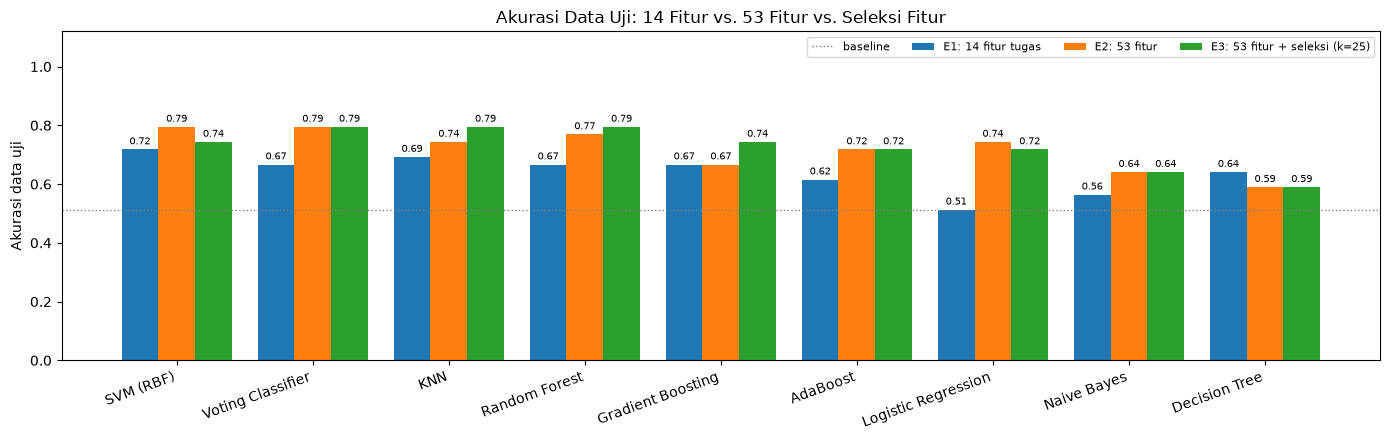

eksperimen,E1: 14 fitur tugas,E2: 53 fitur,E3: 53 fitur + seleksi (k=25)
model,,,
SVM (RBF),0.7179,0.7949,0.7436
Voting Classifier,0.6667,0.7949,0.7949
KNN,0.6923,0.7436,0.7949
Random Forest,0.6667,0.7692,0.7949
Gradient Boosting,0.6667,0.6667,0.7436
AdaBoost,0.6154,0.7179,0.7179
Logistic Regression,0.5128,0.7436,0.7179
Naive Bayes,0.5641,0.6410,0.6410
Decision Tree,0.6410,0.5897,0.5897


In [13]:
import numpy as np
import matplotlib.pyplot as plt

tabel_uji = df_hasil.pivot(index="model", columns="eksperimen", values="acc_test")[list(EKSPERIMEN)]
tabel_uji = tabel_uji.loc[tabel_uji.mean(axis=1).sort_values(ascending=False).index]

x = np.arange(len(tabel_uji))
lebar = 0.27
fig, ax = plt.subplots(figsize=(14, 4.5))
for k, eksp in enumerate(tabel_uji.columns):
    batang = ax.bar(x + (k - 1) * lebar, tabel_uji[eksp], lebar, label=eksp)
    ax.bar_label(batang, fmt="%.2f", fontsize=7, padding=2)
ax.axhline(BASELINE_UJI, color="gray", linestyle=":", lw=1, label="baseline")
ax.set_xticks(x, tabel_uji.index, rotation=20, ha="right")
ax.set(ylim=(0, 1.12), ylabel="Akurasi data uji", title="Akurasi Data Uji: 14 Fitur vs. 53 Fitur vs. Seleksi Fitur")
ax.legend(loc="upper right", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

tabel_uji.round(4)

### 5.2 Validasi Silang Berulang
Data uji hanya sekitar 20% data, sehingga satu kali pembagian bisa kebetulan mudah atau sulit. Setiap model terlatih diuji ulang dengan **`RepeatedStratifiedKFold` (5-fold × 3 ulangan = 15 pembagian)** pada seluruh data, lalu akurasinya dirata-rata. Model terbaik ditentukan dari nilai ini karena lebih stabil. Hasil disimpan ke `hasil2/validasi_silang.csv`.

In [14]:
import os
import warnings
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

warnings.filterwarnings("ignore", category=FutureWarning)
BASELINE = y.value_counts(normalize=True).max()
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

baris = []
for (eksp, nama), model in model_terlatih.items():
    fitur = EKSPERIMEN[eksp][0]
    skor = cross_val_score(clone(model), X_semua[fitur], y, cv=rcv, scoring="accuracy")
    baris.append({"eksperimen": eksp, "model": nama, "akurasi_rata2": skor.mean(), "akurasi_std": skor.std(),
                  "akurasi_min": skor.min(), "akurasi_maks": skor.max()})

validasi = pd.DataFrame(baris).sort_values("akurasi_rata2", ascending=False).reset_index(drop=True)
validasi.round(4).to_csv(os.path.join(FOLDER_HASIL, "validasi_silang.csv"), index=False)

ringkas = validasi.pivot(index="model", columns="eksperimen", values="akurasi_rata2")[list(EKSPERIMEN)]
ringkas.loc["Rata-rata 9 model"] = ringkas.mean()
ringkas.loc["Terbaik"] = ringkas.drop("Rata-rata 9 model").max()
print(f"Baseline (menebak kelas terbanyak): {BASELINE:.4f}\n")
ringkas.round(4)

Baseline (menebak kelas terbanyak): 0.5000



eksperimen,E1: 14 fitur tugas,E2: 53 fitur,E3: 53 fitur + seleksi (k=25)
model,,,
AdaBoost,0.6153,0.7595,0.7770
Decision Tree,0.5862,0.6358,0.6546
Gradient Boosting,0.6393,0.7595,0.7627
KNN,0.6821,0.8163,0.7904
Logistic Regression,0.6273,0.7266,0.7423
Naive Bayes,0.5773,0.6876,0.6563
Random Forest,0.6497,0.7595,0.7543
SVM (RBF),0.6668,0.8335,0.7631
Voting Classifier,0.6582,0.7715,0.7732


#### Cara Membaca
- Bandingkan kolom **E1** dengan **E2/E3**: kenaikan baris *Rata-rata 9 model* dan *Terbaik* menunjukkan seberapa besar fitur revisi membantu.
- Semua nilai sebaiknya jauh di atas *baseline*. Model yang mendekati *baseline* tidak lebih baik dari menebak.
- Selisih antar-model yang lebih kecil dari standar deviasinya (lihat `hasil2/validasi_silang.csv`) belum dapat dianggap perbedaan nyata.

### 5.3 Model Terbaik: Evaluasi Diagnostik
Model terbaik = kombinasi eksperimen dan model dengan **rata-rata akurasi validasi silang tertinggi**. Ditampilkan:
1. *Confusion matrix* pada **data uji**.
2. *Confusion matrix* seluruh data dengan `cross_val_predict` (setiap citra diprediksi oleh model yang tidak dilatih dengan citra itu).

| Metrik | Arti |
| :--- | :--- |
| **Precision** | dari semua citra yang diprediksi kelas X, berapa yang benar kelas X |
| **Recall** | dari semua citra kelas X, berapa yang berhasil dikenali |
| **F1-score** | rata-rata harmonis *precision* dan *recall* |

=== MODEL TERBAIK: SVM (RBF) | E2: 53 fitur ===
Parameter : {'C': 10, 'gamma': 0.01}
Akurasi validasi silang : 83.35% ± 4.63%
Akurasi data uji        : 79.49% (31 dari 39)
Akurasi cross_val_predict: 86.08% (167 dari 194)

Classification report (seluruh data, cross_val_predict):
              precision    recall  f1-score   support

        rapi     0.8571    0.8660    0.8615        97
  berantakan     0.8646    0.8557    0.8601        97

    accuracy                         0.8608       194
   macro avg     0.8609    0.8608    0.8608       194
weighted avg     0.8609    0.8608    0.8608       194



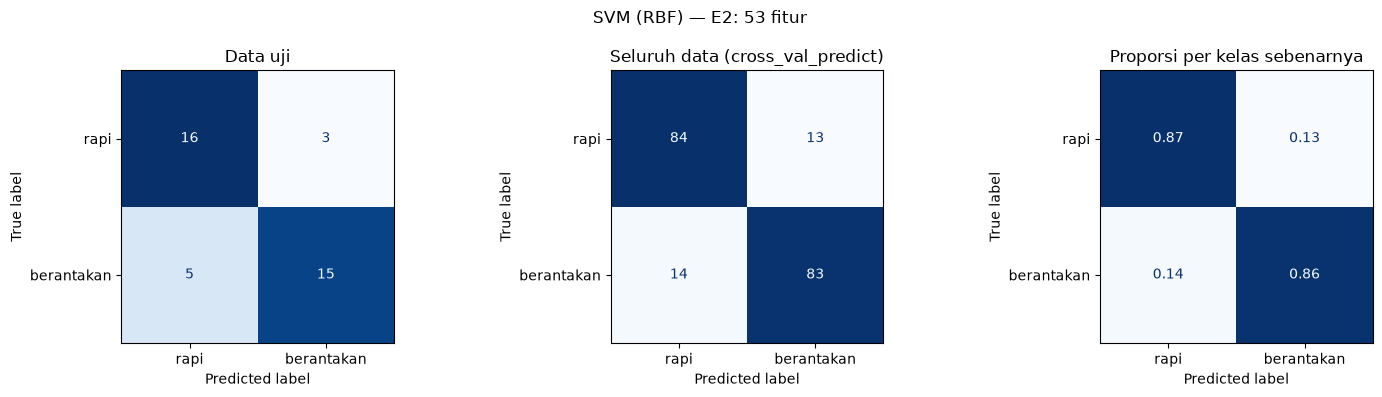

In [15]:
import warnings
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

warnings.filterwarnings("ignore", category=FutureWarning)

EKSP_TERBAIK, MODEL_TERBAIK = validasi.loc[0, ["eksperimen", "model"]]
FITUR_TERBAIK = EKSPERIMEN[EKSP_TERBAIK][0]
model_terbaik = model_terlatih[(EKSP_TERBAIK, MODEL_TERBAIK)]

pred_uji = model_terbaik.predict(X_semua.loc[idx_uji, FITUR_TERBAIK])
pred_semua = cross_val_predict(clone(model_terbaik), X_semua[FITUR_TERBAIK], y,
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))

print(f"=== MODEL TERBAIK: {MODEL_TERBAIK} | {EKSP_TERBAIK} ===")
print("Parameter :", df_hasil.set_index(["eksperimen", "model"]).loc[(EKSP_TERBAIK, MODEL_TERBAIK), "parameter"])
print(f"Akurasi validasi silang : {validasi.loc[0, 'akurasi_rata2']:.2%} ± {validasi.loc[0, 'akurasi_std']:.2%}")
print(f"Akurasi data uji        : {accuracy_score(y_test, pred_uji):.2%} ({(pred_uji == y_test).sum()} dari {len(y_test)})")
print(f"Akurasi cross_val_predict: {accuracy_score(y, pred_semua):.2%} ({(pred_semua == y).sum()} dari {len(y)})\n")
print("Classification report (seluruh data, cross_val_predict):")
print(classification_report(y, pred_semua, labels=KELAS, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_uji, labels=KELAS), display_labels=KELAS).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Data uji")
ConfusionMatrixDisplay(confusion_matrix(y, pred_semua, labels=KELAS), display_labels=KELAS).plot(
    ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Seluruh data (cross_val_predict)")
ConfusionMatrixDisplay(confusion_matrix(y, pred_semua, labels=KELAS, normalize="true"), display_labels=KELAS).plot(
    ax=axes[2], cmap="Blues", colorbar=False, values_format=".2f")
axes[2].set_title("Proporsi per kelas sebenarnya")
plt.suptitle(f"{MODEL_TERBAIK} — {EKSP_TERBAIK}")
plt.tight_layout()
plt.show()

### 5.4 *Confusion Matrix* 9 Model pada Eksperimen Terbaik

---

## TAHAP 6: DEPLOYMENT (Penerapan Model)

### 6.1 Penyimpanan Model
Model terbaik dilatih ulang pada **seluruh data**, lalu disimpan bersama daftar fiturnya ke `hasil2/model_terbaik.joblib`. `StandardScaler` dan `SelectKBest` (jika dipakai) sudah ada di dalam `Pipeline`, sehingga tersimpan otomatis.

In [20]:
import os
import warnings
import joblib
from sklearn.base import clone

warnings.filterwarnings("ignore", category=FutureWarning)
model_final = clone(model_terbaik).fit(X_semua[FITUR_TERBAIK], y)
paket = {"model": model_final, "fitur": FITUR_TERBAIK, "nama_model": MODEL_TERBAIK,
         "eksperimen": EKSP_TERBAIK, "ukuran": UKURAN}
joblib.dump(paket, os.path.join(FOLDER_HASIL, "model_terbaik.joblib"))
print("Model disimpan ke:", os.path.join(FOLDER_HASIL, "model_terbaik.joblib"))
print("Model / eksperimen:", MODEL_TERBAIK, "/", EKSP_TERBAIK, "| jumlah fitur:", len(FITUR_TERBAIK))

Model disimpan ke: hasil2\model_terbaik.joblib
Model / eksperimen: SVM (RBF) / E2: 53 fitur | jumlah fitur: 53


### 6.2 Fungsi Prediksi Citra Baru
Alur prediksi satu foto memakai langkah yang **sama persis** dengan saat pelatihan:

```
Foto baru (JPG/PNG)
  └─ Preprocessing: BGR → RGB, resize 256×256, grayscale 8 bit
       └─ Ekstraksi fitur (RGB, GLCM, HSV, tepi, kontur, orientasi, spasial, ORB, LBP)
            └─ Pilih kolom fitur sesuai model tersimpan
                 └─ Model (Pipeline: standardisasi → [seleksi] → klasifikasi)
                      └─ Hasil: "rapi" / "berantakan"
```

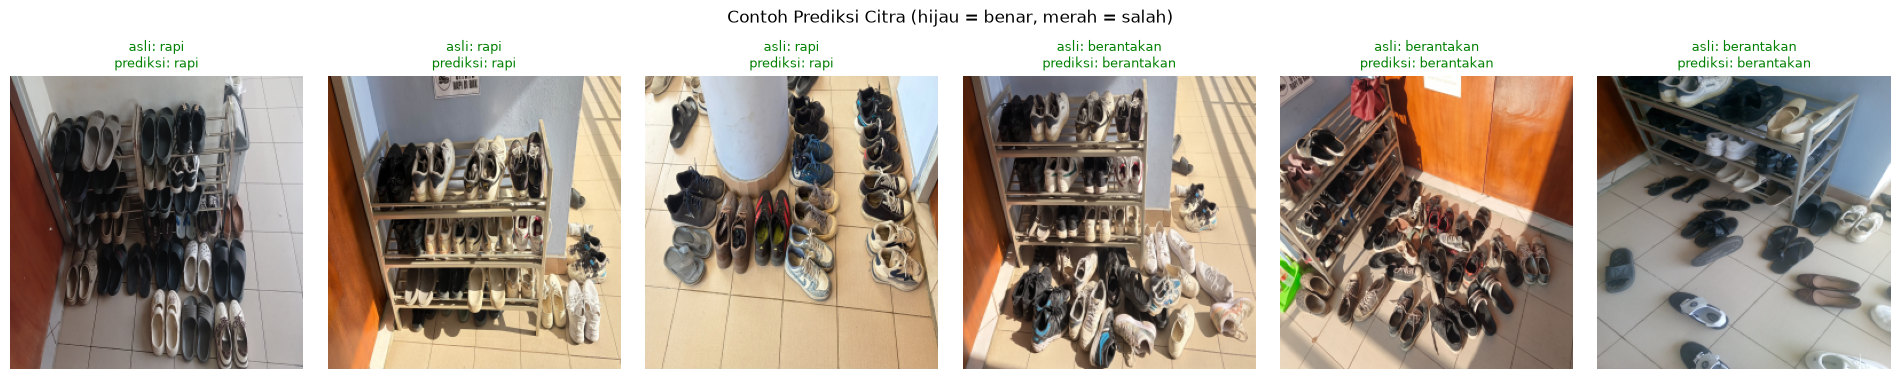

In [21]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def prediksi_citra(path, file_model=os.path.join(FOLDER_HASIL, "model_terbaik.joblib")):
    paket = joblib.load(file_model)
    rgb = preprocessing(path)
    gray = ke_gray(rgb)
    f = {**fitur_rgb(rgb.astype(np.float64)), **fitur_glcm(gray), **fitur_hsv(rgb), **fitur_tepi_kontur(gray),
         **fitur_orientasi(gray), **fitur_spasial(gray), **fitur_orb(gray), **fitur_lbp(gray)}
    x = pd.DataFrame([f])[paket["fitur"]]
    return paket["model"].predict(x)[0], rgb

# Contoh: prediksi 3 citra rapi dan 3 citra berantakan dari dataset
contoh_uji = df.loc[df.index.isin(idx_uji)].groupby("label").head(3)
fig, axes = plt.subplots(1, len(contoh_uji), figsize=(3.2 * len(contoh_uji), 3.6))
for ax, (_, r) in zip(axes, contoh_uji.iterrows()):
    hasil_pred, rgb = prediksi_citra(r["path"])
    ax.imshow(rgb)
    ax.set_title(f"asli: {r['label']}\nprediksi: {hasil_pred}", fontsize=9,
                 color="green" if hasil_pred == r["label"] else "red")
    ax.axis("off")
plt.suptitle("Contoh Prediksi Citra (hijau = benar, merah = salah)", y=1.04)
plt.tight_layout()
plt.show()

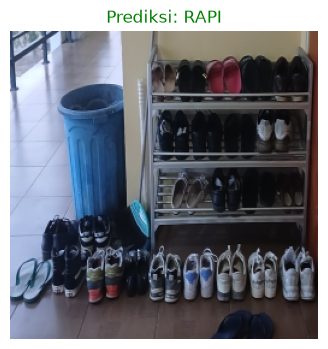

24-006 Rapi 3.jpg -> rapi


In [22]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Muat model yang sudah disimpan
paket = joblib.load(os.path.join(FOLDER_HASIL, "model_terbaik.joblib"))

# 2. Pilih foto (Google Colab: tombol upload | Jupyter/VS Code: jendela pilih file)
try:
    from google.colab import files
    unggahan = files.upload()
    daftar_foto = list(unggahan.keys())
except ImportError:
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
    daftar_foto = filedialog.askopenfilenames(title="Pilih foto sepatu",
                                              filetypes=[("Gambar", "*.jpg *.jpeg *.png *.bmp *.webp")])
    root.destroy()

# 3. Prediksi setiap foto dengan langkah yang sama seperti saat pelatihan
for path in daftar_foto:
    rgb = preprocessing(path)
    gray = ke_gray(rgb)
    fitur = {**fitur_rgb(rgb.astype(np.float64)), **fitur_glcm(gray), **fitur_hsv(rgb),
             **fitur_tepi_kontur(gray), **fitur_orientasi(gray), **fitur_spasial(gray),
             **fitur_orb(gray), **fitur_lbp(gray)}
    hasil = paket["model"].predict(pd.DataFrame([fitur])[paket["fitur"]])[0]

    plt.figure(figsize=(4, 4))
    plt.imshow(rgb)
    plt.title(f"Prediksi: {hasil.upper()}", color="green" if hasil == "rapi" else "red")
    plt.axis("off")
    plt.show()
    print(f"{os.path.basename(path)} -> {hasil}")